# Proyecto N-2: Optimización de Marketing Digital (A/B Testing)

**Autor:** Juan Carlos Muñoz
**Fecha:** 23/09/2026
**Dataset:** Marketing A/B Test - Synthetic (Known Uplift)

**Objetivo:** Determinar si la nueva Página B mejora la conversión respecto
a la Página A en un e-commerce de moda.

**Estructura:**
- F-1: Entendimiento del negocio
- F-2: Adquisición de datos
- F-3: Limpieza y auditoría del experimento
- F-4: Análisis exploratorio
- F-5: Test estadístico (Chi-Cuadrado)
- F-6: Evaluación y recomendación
- F-7: Comunicación

In [1]:
import pandas as pd
market = pd.read_csv("ab_test.csv")
print(market.head())
print(market.info())

   user_id  age   device country  tenure_days  prior_purchases      group  \
0  U300000   44  desktop      US          793                1  treatment   
1  U300001   33   mobile      US          898                3    control   
2  U300002   37   mobile      US          186                1  treatment   
3  U300003   29   mobile      US            6                0  treatment   
4  U300004   47   mobile      US          102                0    control   

   converted  
0          1  
1          0  
2          0  
3          0  
4          0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   user_id          40000 non-null  object
 1   age              40000 non-null  int64 
 2   device           40000 non-null  object
 3   country          40000 non-null  object
 4   tenure_days      40000 non-null  int64 
 5   prior_purchases  40

In [2]:
market["group"].value_counts()

,count
group,
treatment,20019
control,19981


## Concepto de F-3 en A/B Testing: Auditoría de validez del experimento
Antes de calcular conversiones, hay que verificar tres cosas que pueden invalidar todo el experimento. Este es el concepto central de F-3 en N-2.

Las 3 auditorías obligatorias
1. Duplicados de usuario (user_id)
Si un mismo usuario aparece varias veces, puede haber sido contado dos veces (una en cada grupo, o dos veces en el mismo). Eso rompe la independencia de las observaciones.

2. Balance de variables entre grupos (variables de confusión)
Ya verificaste el balance de tamaño (50/50). Ahora toca verificar el balance de características: ¿age, device, country, tenure_days y prior_purchases están repartidas por igual entre A y B? Si no, son confusoras potenciales.

3. Valores imposibles o inconsistentes
Ejemplos: age negativa, tenure_days mayor que la edad del e-commerce, prior_purchases negativas, converted con valores distintos de 0/1, group con valores distintos de control/treatment.

In [3]:
# TODO 1: verifica si hay user_id duplicados
# Pista: usa df['user_id'].duplicated().sum()
print(market["user_id"].duplicated().sum())

0


In [4]:
# TODO 2: para las columnas categóricas ('device', 'country'),
# muestra la distribución porcentual por grupo
# Pista: usa df.groupby('group')['device'].value_counts(normalize=True)
print(market.groupby('group')['device'].value_counts(normalize=True))
# Repite lo mismo para 'country'
print(market.groupby('group')['country'].value_counts(normalize=True))

group      device 
control    mobile     0.622742
           desktop    0.377258
treatment  mobile     0.623308
           desktop    0.376692
Name: proportion, dtype: float64
group      country
control    US         0.391622
           UK         0.150993
           IN         0.149642
           CA         0.125419
           DE         0.103548
           AU         0.078775
treatment  US         0.400070
           UK         0.149608
           IN         0.148309
           CA         0.121584
           DE         0.102003
           AU         0.078425
Name: proportion, dtype: float64


In [5]:
# TODO 3: compara la media de 'age', 'tenure_days' y 'prior_purchases'
# entre control y treatment
# Pista: usa df.groupby('group')[['age', 'tenure_days', 'prior_purchases']].mean()
print(market.groupby('group')[['age','tenure_days','prior_purchases']].mean())

                 age  tenure_days  prior_purchases
group                                             
control    36.173865   219.541564         0.938141
treatment  36.200759   218.988061         0.922723


In [6]:
# TODO 4: verifica que 'converted' solo tenga valores 0 y 1
# y que 'group' solo tenga 'control' y 'treatment'
# Pista: usa df['converted'].unique() y df['group'].unique()
print(market['converted'].unique())
print(market['group'].unique())

[1 0]
['treatment' 'control']


## Conclusión de F-3
El experimento es válido. Las variables están balanceadas entre grupos. La aleatorización funcionó correctamente. No hay duplicados ni valores imposibles.

En F-3 auditamos las variables candidatas a confusoras (device, country, age, tenure_days, prior_purchases) comparando su distribución entre control y treatment. Usamos value_counts para categóricas y medias por grupo para numéricas. Conclusión: todas las diferencias son menores a 1 punto porcentual o ínfimas → la aleatorización funcionó → el experimento es válido.

## Consecuencia:
Podemos proceder al análisis sin limitaciones estructurales. Las variables age, device, country, tenure_days y prior_purchases no son confusoras — están repartidas por igual.

## Cálculo de tasa de conversión por grupo

**Qué buscamos:** la tasa de conversión (proporción de usuarios que compraron) para los grupos control y treatment.

**Por qué:** es el número crudo que compararemos para responder la pregunta del Director.

**Decisión previa:** usamos `converted` como métrica (proporción, no media), definida en F-1.

# F-4: Análisis Exploratorio de Datos (EDA)

**Objetivo de esta fase:** entender el comportamiento de la métrica `converted`
por grupo, y preparar el terreno para el test estadístico de F-5.

**Qué haremos:**
1. Calcular la tasa de conversión por grupo (el número crudo a comparar).
2. Visualizar la comparación con barras.
3. Ver el volumen detrás de la tasa con barras apiladas.
4. Simular la distribución muestral con bootstrap (conexión con el TLC).

**Qué NO haremos:**
- No describiremos todas las columnas (eso fue N-1).
- No aplicaremos pruebas estadísticas (eso es F-5).

**Entregables:** tasa por grupo + 3 visualizaciones adaptadas a métrica binaria.

**Decisiones registradas:**
- Decisión N-2 #3: Adaptar las 3 visualizaciones al contexto de métrica binaria.

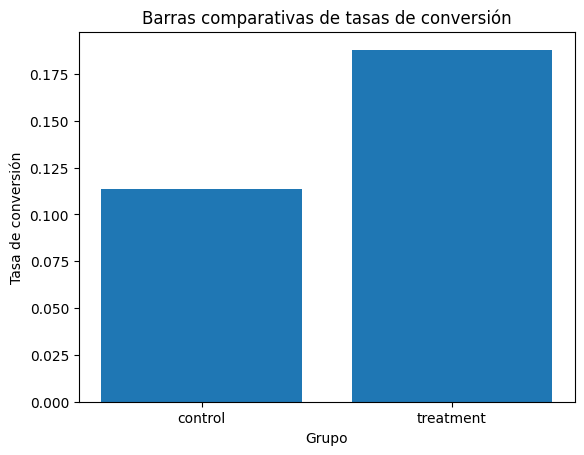

In [7]:
## Bloque 1 — Tasa de conversión por grupo
#**Qué buscamos:** la proporción de usuarios que compraron en cada grupo.
#**Por qué:** es el número crudo que compararemos para responder la pregunta del Director.
import matplotlib.pyplot as plt
tasas = market.groupby('group')['converted'].mean()
plt.bar(tasas.index, tasas.values)
plt.title("Barras comparativas de tasas de conversión")
plt.xlabel("Grupo")
plt.ylabel("Tasa de conversión")
plt.show()


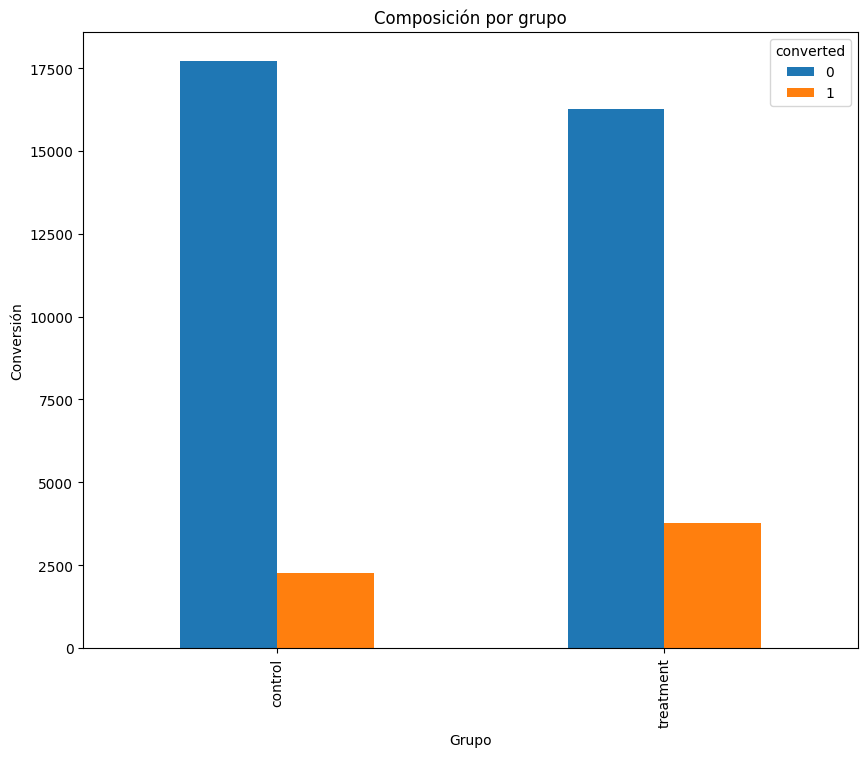

In [8]:
## Bloque 3 — Composición 0/1 por grupo
#**Qué buscamos:** ver cuántos usuarios convirtieron y no convirtieron en cada grupo.
composicion = pd.crosstab(market['group'], market['converted'])
composicion.plot(kind='bar' ,figsize=(10,8))
plt.title('Composición por grupo')
plt.xlabel('Grupo')
plt.ylabel('Conversión')
plt.show()


**Hallazgo:**
- Control: 11.36% de conversión
- Treatment: 18.79% de conversión
- Diferencia: +7.43 puntos porcentuales (+65% relativo)

**Implicación:**
La Página B (treatment) convierte notablemente más que la Página A (control)
en la muestra. Sin embargo, esto es descriptivo: aún no podemos afirmar que
la diferencia sea real y no producto del azar. Eso se confirmará en F-5 con
el test estadístico.

In [9]:
## Bloque 4 — Distribución muestral de la tasa de conversión (bootstrap)
#Qué buscamos:** visualizar cómo varía la tasa de conversión si repitiéramos el experimento muchas veces.
#Por qué:** conecta con el Teorema del Límite Central y prepara el terreno para el test estadístico de F-5.

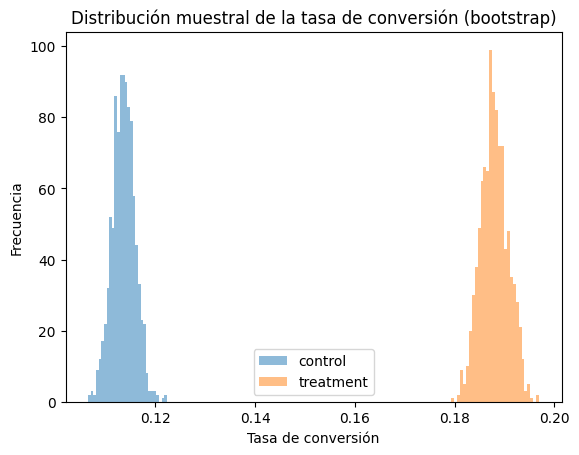

In [10]:
import numpy as np
control = market[market['group'] == "control"]["converted"].values
treatment = market[market['group']=='treatment']["converted"].values

medias_control = []
for x in range(1000):
  muestra = np.random.choice(control, size = len(control), replace= True)
  medias_control.append(muestra.mean())

medias_treatment = []
for x in range(1000):
  muestra = np.random.choice(treatment, size= len(treatment), replace= True)
  medias_treatment.append(muestra.mean())

plt.hist(medias_control, bins=30, alpha=0.5, label='control')
plt.hist(medias_treatment, bins=30, alpha=0.5, label='treatment')
plt.legend()
plt.title("Distribución muestral de la tasa de conversión (bootstrap)")
plt.xlabel("Tasa de conversión")
plt.ylabel("Frecuencia")
plt.show()

**Hallazgo:**
- Control: campana centrada en ~0.113 (11.3%)
- Treatment: campana centrada en ~0.188 (18.8%)
- Ambas siguen una distribución normal (TLC en acción)
- Las dos campanas están completamente separadas, sin solapamiento

**Implicación:**
La distribución muestral confirma visualmente el TLC: aunque los datos
individuales son binarios (0/1), las medias bootstrap se distribuyen
normalmente. La separación total entre ambas campanas sugiere que la
diferencia entre grupos es muy probablemente real y no producto del azar.
Sin embargo, la confirmación formal requiere el test estadístico de F-5.

# Fase-5
## Bloque 1 — Test Chi-Cuadrado de independencia

**Qué buscamos:** determinar si la diferencia en conversión entre control y
treatment es estadísticamente significativa o producto del azar.

**Por qué:** es la prueba formal que responde la pregunta del Director.

**Decisión previa:** usamos Chi-Cuadrado porque la métrica es una proporción
y tenemos 2 grupos (2×2).

**Hipótesis:**
- H₀: `group` y `converted` son independientes (no hay diferencia real).
- H₁: `group` y `converted` están asociados (sí hay diferencia real).

In [11]:
# TODO 1: importa chi2_contingency desde scipy.stats
from scipy.stats import chi2_contingency

# TODO 2: crea la tabla de contingencia group vs converted
# Pista: usa pd.crosstab(df['group'], df['converted'])
tab = pd.crosstab(market['group'], market['converted'])

# TODO 3: aplica chi2_contingency sobre la tabla
# Pista: chi2, p_value, dof, expected = chi2_contingency(tabla)
chi2, p_value, dof, expected = chi2_contingency(tab)

# TODO 4: imprime chi2, p_value y dof
print(f"Chi2: {chi2}\nP_value: {p_value}\nDof: {dof}")

Chi2: 431.30454800427634
P_value: 8.451898485971657e-96
Dof: 1


**Hallazgo:**
- chi2 = 431.30
- p-value = 8.45 × 10⁻⁹⁶
- grados de libertad = 1

**Implicación:**
El p-value es prácticamente cero, muy por debajo de α = 0.05.
Rechazamos H₀: `group` y `converted` no son independientes.
Hay evidencia estadística abrumadora de que la Página B convierte
distinto que la Página A. La diferencia observada no es producto del azar.

## Bloque 1 — Tamaño del efecto

**Qué buscamos:** cuantificar qué tan grande es la diferencia entre control y treatment.

**Por qué:** el p-value dice que hay diferencia, pero no dice si esa diferencia importa para el negocio.

**Insumo:** tasas de conversión calculadas en F-4.

In [12]:
# TODO 1: recupera las tasas de conversión por grupo
# Pista: usa tasas = df.groupby('group')['converted'].mean()
# TODO 2: calcula la diferencia absoluta (treatment - control)
# Pista: usa tasas['treatment'] - tasas['control']
dif_abs = abs(tasas['treatment'] - tasas['control'])

# TODO 3: calcula la diferencia relativa ((treatment - control) / control)
# Pista: (tasas['treatment'] - tasas['control']) / tasas['control']
dif_rel = (tasas['treatment']-tasas['control']) /tasas['control']
# TODO 4: imprime ambos valores
print(f"La diferencia absoluta es_ {dif_abs}\nLa diferencia relativa es: {dif_rel}%")

La diferencia absoluta es_ 0.07436359461314415
La diferencia relativa es: 0.6548519100772293%


**Hallazgo:**
- Diferencia absoluta: +7.44 puntos porcentuales
- Diferencia relativa: +65.49%

**Implicación:**
La diferencia entre treatment y control no solo es estadísticamente significativa
(p ≈ 0), sino que es grande en magnitud. Treatment convierte un 65.49% más que
control. Para el Director, esta cifra relativa es la más expresiva: indica que
el cambio no es marginal, sino sustancial.

## Bloque 2 — Errores Tipo I y Tipo II

**Qué buscamos:** identificar los dos tipos de error posibles al tomar una
decisión basada en un test de hipótesis.

**Por qué:** toda decisión estadística tiene un riesgo de equivocarse.
Reconocerlo es parte de una conclusión honesta.

**Contexto:** ya tomamos la decisión de rechazar H₀. Ahora vamos a nombrar
qué tipo de error podríamos estar cometiendo.

**Hallazgo:**
- Error Tipo I (falso positivo): rechazar H₀ cuando era cierta. Probabilidad = α = 5%.
- Error Tipo II (falso negativo): no rechazar H₀ cuando era falsa. Probabilidad = β.

**Implicación:**
En este caso, ambos errores son improbables, pero el Tipo II es especialmente bajo
porque el efecto es grande (+65%) y la muestra también (~20,000 por grupo).
El error más preocupante para el negocio sería el Tipo II: descartar una página
que realmente mejora la conversión implicaría perder una ganancia sustancial
acumulada mes a mes.

## Bloque 3 — Recomendación al Director

**Qué buscamos:** traducir todo el análisis estadístico a una decisión de negocio.

**Por qué:** el Director no necesita p-values ni chi2. Necesita saber qué hacer
con la Página B.

**Insumos:**
- Significancia: p ≈ 0 → hay diferencia real.
- Tamaño del efecto: +7.44 pp / +65.49%.
- Errores posibles: Tipo II es el más preocupante, pero improbable.


**Hallazgo:**
- Decisión: mantener la Página B.
- Confianza: 95%.
- Impacto: +65.49% de conversión relativa.
- Errores: Tipo I (5%, por α), Tipo II (muy improbable).

**Implicación:**
La evidencia estadística respalda mantener la Página B. La ganancia en conversión
es sustancial y el riesgo de error es bajo. Se recomienda al Director implementar
la Página B de forma permanente.

## Registro de decisiones

- Decisión N-2 #1: Métrica elegida = conversión (proporción), definida en F-1.
- Decisión N-2 #2: Dataset elegido = "Marketing A/B Test - Synthetic (Known Uplift)" por tener ground truth verificable.
- Decisión N-2 #3: Adaptar las 3 visualizaciones al contexto de métrica binaria.
- Decisión N-2 #4: Usar Chi-Cuadrado en lugar de T-Test porque la métrica es una proporción.
- Decisión N-2 #5: Mantener la Página B, con 95% de confianza y ganancia esperada de +65.49%.